# End-to-End NCS Inference Walkthrough

This notebook shows a complete workflow:

1. Configure a pretrained NCS model and a seismic input volume.
2. Run feature extraction with `NCS.inference.run_inference`.
3. Reload the saved feature cube from the direction group.
4. Inspect the output dataset and channel statistics.
5. Pick a reference location and visualize cosine similarity maps.


## Environment setup

Recommended setup from the repository root:

```bash
uv sync --extra inference --group dev
```

You must also provide your own seismic input file path below.


In [ ]:
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from IPython.display import display

from NCS.inference import run_inference

In [2]:
# Top-level configuration.
# Change MODEL_PRESET to switch models.

MODEL_PRESETS = {
    "2d": {
        "model_path": "NorskRegnesentralSTI/NCS-v1-2d-base",
        "batch_size": 64,
        "input_views": None,
    },
    "2.5d": {
        "model_path": "NorskRegnesentralSTI/NCS-v1-2.5d-base",
        "batch_size": 32,
        "input_views": None,
    },
    "3d": {
        "model_path": "NorskRegnesentralSTI/NCS-v1-3d-base",
        "batch_size": 4,
        "input_views": None,
    },
}

MODEL_PRESET = "3d"
SETTINGS = MODEL_PRESETS[MODEL_PRESET]

INPUT_PATH = Path("../../Dutch Government_F3_entire_8bit seismic.segy")  # Update this to your own SEG-Y or SGZ file.
DIRECTION = "dir0"
OUTPUT_PATH = Path("./outputs") / f"notebook_{MODEL_PRESET}_{DIRECTION}.zarr"

RUN_INFERENCE = True
OVERWRITE_OUTPUT = False

CROP_SIZE = 224
PATCH_SIZE = 16
DENSIFY = 1
NUM_OVERLAP_PATCHES = 3
OVERLAP_FILTER = "ramp"
DEVICE = "cuda"
DTYPE = "float16"
NORMALIZATION_MODE = "std"
NUM_WORKERS = 4
PREFETCH_FACTOR = 2
MAX_PRELOAD = 10

REF_IL: int = 25  # inline patch index
REF_XL: int = 40  # crossline patch index
REF_T: int = 20  # depth/time patch index
REFERENCE_INDEX = (
    REF_IL,
    REF_XL,
    REF_T,
)  # Set to (inline_idx, xline_idx, time_idx) to override the default center point.

print(f"Model preset: {MODEL_PRESET}")
print(f"Model path:   {SETTINGS['model_path']}")
print(f"Input path:   {INPUT_PATH}")
print(f"Output path:  {OUTPUT_PATH}")

Model preset: 3d
Model path:   NorskRegnesentralSTI/NCS-v1-3d-base
Input path:   ../../Dutch Government_F3_entire_8bit seismic.segy
Output path:  outputs/notebook_3d_dir0.zarr


In [3]:
if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Input seismic file not found: {INPUT_PATH}. Update INPUT_PATH in the configuration cell first."
    )

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

if OUTPUT_PATH.exists() and OVERWRITE_OUTPUT:
    if OUTPUT_PATH.is_dir() and not OUTPUT_PATH.is_symlink():
        shutil.rmtree(OUTPUT_PATH)
    else:
        OUTPUT_PATH.unlink()

if RUN_INFERENCE:
    ds_written = run_inference(
        model_path=SETTINGS["model_path"],
        input_path=INPUT_PATH,
        output_path=OUTPUT_PATH,
        direction=DIRECTION,
        input_views=SETTINGS["input_views"],
        crop_size=CROP_SIZE,
        patch_size=PATCH_SIZE,
        num_overlap_patches=NUM_OVERLAP_PATCHES,
        overlap_filter=OVERLAP_FILTER,
        densify=DENSIFY,
        batch_size=SETTINGS["batch_size"],
        device=DEVICE,
        dtype=DTYPE,
        normalization_mode=NORMALIZATION_MODE,
        num_workers=NUM_WORKERS,
        prefetch_factor=PREFETCH_FACTOR,
        max_preload=MAX_PRELOAD,
    )
    print(f"Inference completed. In-memory dataset dims: {dict(ds_written.sizes)}")
else:
    print("RUN_INFERENCE is False. Reusing an existing output store.")

3D inference: 100%|██████████| 72/72 [00:16<00:00,  4.24it/s]


Inference completed. In-memory dataset dims: {'inline': 41, 'xline': 60, 'time_depth': 29, 'feature': 768}


In [4]:
if OUTPUT_PATH.suffix == ".zarr":
    ds = xr.open_zarr(OUTPUT_PATH, group=DIRECTION)
elif OUTPUT_PATH.suffix == ".nc":
    ds = xr.open_dataset(OUTPUT_PATH, group=DIRECTION)
else:
    raise ValueError(f"Unsupported output format: {OUTPUT_PATH.suffix}")

display(ds)

feature_cube = ds["features"].load()
channel_mean = ds["mean"].values.astype(np.float32)
channel_std = np.maximum(ds["std"].values.astype(np.float32), 1e-6)

print(f"Feature cube shape: {feature_cube.shape}")
print(f"Feature cube dims:  {feature_cube.dims}")
print(f"Mean/std shapes:    {channel_mean.shape}, {channel_std.shape}")

<xarray.Dataset> Size: 219MB
Dimensions:     (inline: 41, xline: 60, time_depth: 29, feature: 768)
Coordinates:
  * inline      (inline) int32 164B 8 24 40 56 72 88 ... 568 584 600 616 632 648
  * xline       (xline) int32 240B 8 24 40 56 72 88 ... 872 888 904 920 936 952
  * time_depth  (time_depth) int32 116B 8 24 40 56 72 88 ... 392 408 424 440 456
Dimensions without coordinates: feature
Data variables:
    features    (inline, xline, time_depth, feature) float32 219MB dask.array<chunksize=(14, 14, 14, 768), meta=np.ndarray>
    mean        (feature) float32 3kB dask.array<chunksize=(768,), meta=np.ndarray>
    std         (feature) float32 3kB dask.array<chunksize=(768,), meta=np.ndarray>

Feature cube shape: (41, 60, 29, 768)
Feature cube dims:  ('inline', 'xline', 'time_depth', 'feature')
Mean/std shapes:    (768,), (768,)


In [5]:
def pick_reference_index(cube: xr.DataArray, requested_index: tuple[int, int, int] | None) -> tuple[int, int, int]:
    spatial_shape = cube.shape[:-1]
    if requested_index is None:
        return tuple(size // 2 for size in spatial_shape)

    if len(requested_index) != 3:
        raise ValueError(f"REFERENCE_INDEX must have length 3, got {requested_index!r}")

    validated = []
    for axis, (idx, size) in enumerate(zip(requested_index, spatial_shape, strict=True)):
        if not 0 <= idx < size:
            raise ValueError(f"REFERENCE_INDEX[{axis}]={idx} is outside the valid range [0, {size}).")
        validated.append(int(idx))
    return tuple(validated)


def compute_cosine_similarity(cube: np.ndarray, reference_feature: np.ndarray) -> np.ndarray:
    flat_cube = cube.reshape(-1, cube.shape[-1])
    normalized_cube = flat_cube / (np.linalg.norm(flat_cube, axis=1, keepdims=True) + 1e-8)
    normalized_reference = reference_feature / (np.linalg.norm(reference_feature) + 1e-8)
    similarity = normalized_cube @ normalized_reference
    return similarity.reshape(cube.shape[:-1])


feature_values = feature_cube.values.astype(np.float32)
standardized_features = (feature_values - channel_mean) / channel_std

reference_index = pick_reference_index(feature_cube, REFERENCE_INDEX)
reference_feature = standardized_features[reference_index]
similarity_map = compute_cosine_similarity(standardized_features, reference_feature)

reference_coords = {
    dim: int(feature_cube.coords[dim].values[idx])
    for dim, idx in zip(feature_cube.dims[:-1], reference_index, strict=True)
}

print(f"Reference index:  {reference_index}")
print(f"Reference coords: {reference_coords}")
print(f"Similarity range: [{similarity_map.min():.3f}, {similarity_map.max():.3f}]")

Reference index:  (25, 40, 20)
Reference coords: {'inline': 408, 'xline': 648, 'time_depth': 328}
Similarity range: [-0.257, 1.000]


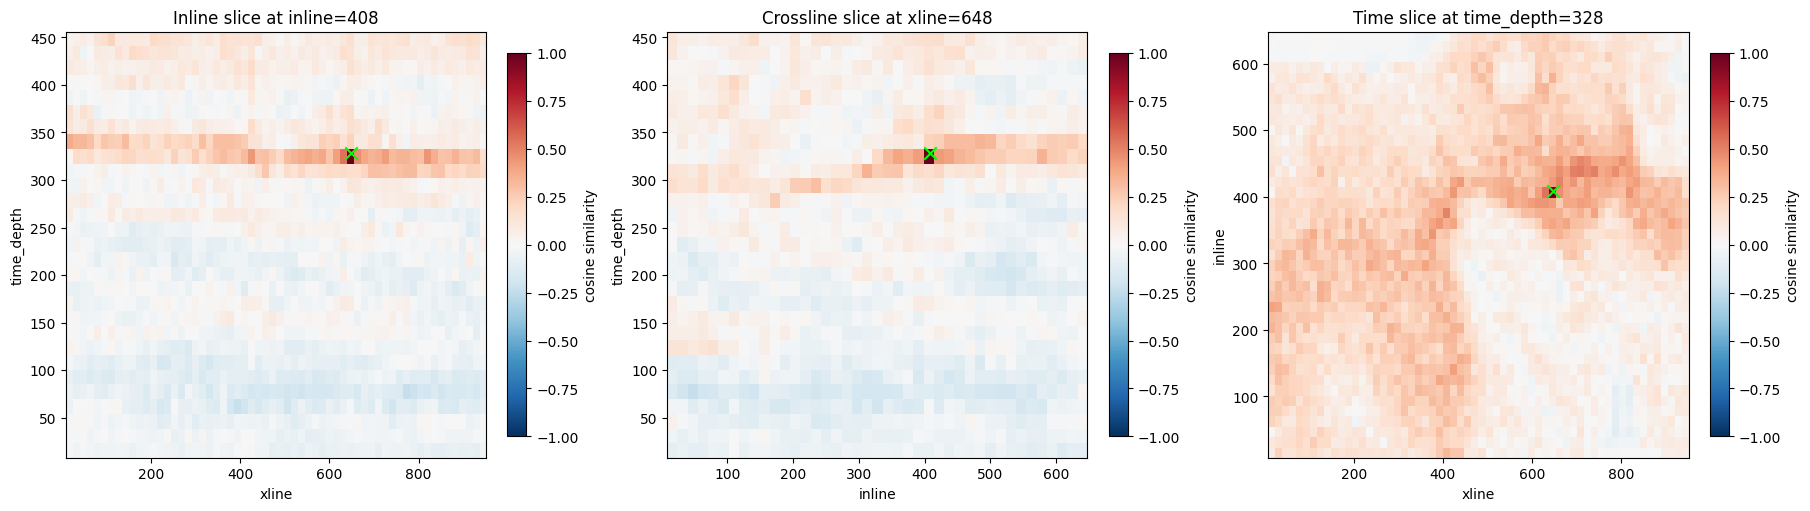

In [6]:
inline_coords = feature_cube.coords["inline"].values
xline_coords = feature_cube.coords["xline"].values
time_coords = feature_cube.coords["time_depth"].values
inline_idx, xline_idx, time_idx = reference_index

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

im0 = axes[0].imshow(
    similarity_map[inline_idx, :, :].T,
    origin="lower",
    aspect="auto",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    extent=[xline_coords[0], xline_coords[-1], time_coords[0], time_coords[-1]],
)
axes[0].set_title(f"Inline slice at inline={inline_coords[inline_idx]}")
axes[0].set_xlabel("xline")
axes[0].set_ylabel("time_depth")
axes[0].scatter(xline_coords[xline_idx], time_coords[time_idx], c="lime", marker="x", s=80)

im1 = axes[1].imshow(
    similarity_map[:, xline_idx, :].T,
    origin="lower",
    aspect="auto",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    extent=[inline_coords[0], inline_coords[-1], time_coords[0], time_coords[-1]],
)
axes[1].set_title(f"Crossline slice at xline={xline_coords[xline_idx]}")
axes[1].set_xlabel("inline")
axes[1].set_ylabel("time_depth")
axes[1].scatter(inline_coords[inline_idx], time_coords[time_idx], c="lime", marker="x", s=80)

im2 = axes[2].imshow(
    similarity_map[:, :, time_idx],
    origin="lower",
    aspect="auto",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    extent=[xline_coords[0], xline_coords[-1], inline_coords[0], inline_coords[-1]],
)
axes[2].set_title(f"Time slice at time_depth={time_coords[time_idx]}")
axes[2].set_xlabel("xline")
axes[2].set_ylabel("inline")
axes[2].scatter(xline_coords[xline_idx], inline_coords[inline_idx], c="lime", marker="x", s=80)

for ax, image in zip(axes, [im0, im1, im2], strict=True):
    colorbar = fig.colorbar(image, ax=ax, shrink=0.9)
    colorbar.set_label("cosine similarity")

plt.show()